# El puntaje, el modelo nulo y el intervalo: juzgar una predicción con el sitio fuera

**Nivel 2: El método en la práctica** · Requiere: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Tiempo de lectura: unos 30 minutos

## Objetivos

Un número como "R2 = 0,94" no significa nada hasta que se nombra el estadístico, se pone una línea base a su lado y se declara la incertidumbre. Este cuaderno define las tres cosas que el producto informa con cada puntaje y luego aplica el criterio predeclarado que decide si el nivel aprendido generaliza entre sitios.

Al terminar habrá:

- puntuado un brazo aprendido con el sitio fuera con dos estadísticos con nombre y puesto el modelo nulo a su lado;
- construido un intervalo de 95 por ciento que remuestrea tiros y uno que remuestrea sitios, y visto cuánto más ancho es el honesto;
- aplicado el criterio de descarte a los brazos corridos aquí y reproducido el veredicto versionado en ambos conjuntos de filas.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.3 matplotlib==3.11.2
```

Esta celda aún no importa nada del cuaderno: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este cuaderno
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el cuaderno |
|---|---|---|---|
| Los 97 tiros | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| Los puntajes, intervalos y veredicto con un sitio fuera versionados | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campos `protocols` y `verdict` |

## Método

**El estadístico.** Dos cantidades llevan el nombre R2 en esta literatura. El motor informa ambas, cada una con su propio nombre:

- `pearson_r2`, la correlación al cuadrado de lo predicho contra lo medido;
- `r2_identity = 1 - sum((medido - predicho)^2) / sum((medido - media(medido))^2)`, la varianza explicada respecto de la línea de identidad, que es negativa cuando las predicciones son peores que la media.

En los 12 tiros del hold-out publicado de Kulatilake, Hudaverdi y Wu 2012 (https://doi.org/10.1007/s10706-012-9496-3) las dos difieren por un factor de dos y medio para las mismas predicciones.

**El nulo.** Un modelo que predice el tamaño medio medido de sus filas de entrenamiento, sin usar ninguna entrada. Se ajusta dentro de cada pliegue, como debe ser.

**El intervalo.** Un bootstrap que remuestrea la unidad de independencia. Bajo un protocolo que deja sitios fuera la unidad es el sitio (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

**El criterio**, declarado en el motor antes de la ejecución: el nivel aprendido cuenta como generalizante entre sitios solo si el `r2_identity` del mejor brazo aprendido con un sitio fuera es positivo y al menos 0,10 sobre el del nulo.

### Paso 1: un sitio fuera para el nulo y tres brazos aprendidos

La celda entrena cada brazo con nueve sitios, predice el décimo, y reúne las predicciones fuera de pliegue de los 97 tiros. Los brazos aprendidos aquí son los de gradient boosting, bosque aleatorio y apilamiento; la escalera completa de catorce brazos se corre en el tema siguiente. Se usan las fábricas que devuelve `default_arms`, de modo que cada pliegue recibe un modelo nuevo.

In [2]:
# Importaciones, y luego predicciones fuera de pliegue para el nulo y tres brazos aprendidos
import hashlib
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
factories = bf.default_arms()
names = ["null", "xgboost", "random-forest", "stacking"]
tested, predictions = [], {n: [] for n in names}
for split in bf.leave_one_site_out(train):
    tested += list(split.test)
    for name in names:
        predictions[name] += factories[name]().fit(split.train).predict(split.test)
print("tiros fuera de pliegue:", len(tested), "| brazos:", names)

tiros fuera de pliegue: 97 | brazos: ['null', 'xgboost', 'random-forest', 'stacking']


### Paso 2: dos estadísticos, y el nulo a su lado

Para cada brazo la celda imprime `pearson_r2` y `r2_identity` en los 97 tiros. El `r2_identity` del nulo es la línea base: un brazo que no lo supera no ha aprendido nada que se transfiera.

In [3]:
# Ambos estadísticos por brazo, y si igualan los valores versionados
print(f"{'brazo':<16}{'Pearson r2':>12}{'r2 identidad':>14}{'RMSE (m)':>10}  igual a versionado")
scores = {}
for name in names:
    s = bf.score(tested, predictions[name], method=name)
    scores[name] = s
    want = loso[name]["supports"]["all"]["score"]["r2_identity"]
    pearson = f"{s.pearson_r2:.4f}" if s.pearson_r2 is not None else "-"
    print(f"{name:<16}{pearson:>12}{s.r2_identity:>14.4f}{s.rmse_m:>10.4f}  {abs(s.r2_identity - want) < 1e-9}")

brazo             Pearson r2  r2 identidad  RMSE (m)  igual a versionado
null                  0.6268       -0.2163    0.2067  True
xgboost               0.1633       -0.0342    0.1906  True
random-forest         0.1034       -0.2315    0.2080  True
stacking              0.1644       -0.0345    0.1906  True


### Paso 3: por qué el nulo merece una segunda mirada

El nulo es la media de entrenamiento, y la media de entrenamiento se mueve cuando se deja un sitio fuera: dejar fuera un sitio grueso la baja, dejar uno fino la sube. La celda correlaciona las predicciones fuera de pliegue del nulo con las mediciones. Una correlación fuertemente negativa significa que cualquier brazo que solo siga la media de entrenamiento parece "mejor que el nulo" sin habilidad.

In [4]:
# Correlación de las predicciones fuera de pliegue del nulo con las mediciones, y el valor versionado
measured = np.array([b.x50_m for b in tested])
null_values = np.array([p.x50_m for p in predictions["null"]])
r = np.corrcoef(measured, null_values)[0, 1]
print(f"correlación del nulo con las mediciones = {r:.4f}")
print(f"versionado: {benchmark['verdict']['null_pearson_r']:.4f}")

correlación del nulo con las mediciones = -0.7917
versionado: -0.7917


### Paso 4: el intervalo, remuestreando tiros y remuestreando sitios

`bootstrap_interval` recibe una `unit`. Con `unit="blast"` cada sorteo remuestrea las 97 filas con reemplazo; con `unit="site"` remuestrea las diez campañas, tomando cada una con todas sus filas. La celda calcula ambos para el brazo de gradient boosting con 2000 sorteos y la semilla del benchmark, y compara el intervalo por sitio con el versionado.

unit = blast  r2_identity -0.0342   95 %: -0.382 a 0.208   ancho 0.591
unit = site   r2_identity -0.0342   95 %: -2.232 a 0.418   ancho 2.650
el intervalo por sitio iguala al versionado: True


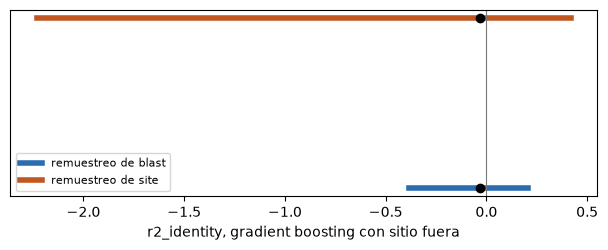

In [5]:
# Intervalos de 95 por ciento para el brazo de gradient boosting bajo las dos unidades de remuestreo
intervals = {}
for unit in ("blast", "site"):
    point, low, high = bf.bootstrap_interval(tested, predictions["xgboost"], "r2_identity", n_boot=2000, unit=unit, seed=0)
    intervals[unit] = (point, low, high)
    print(f"unit = {unit:<6} r2_identity {point:.4f}   95 %: {low:.3f} a {high:.3f}   ancho {high - low:.3f}")
want = loso["xgboost"]["supports"]["all"]["interval_95"]
print("el intervalo por sitio iguala al versionado:", abs(intervals["site"][1] - want[0]) < 1e-9 and abs(intervals["site"][2] - want[1]) < 1e-9)

fig, ax = plt.subplots(figsize=(6.2, 2.6))
for row, (unit, (point, low, high)) in enumerate(intervals.items()):
    ax.plot([low, high], [row, row], lw=4, color="#2b6cb0" if unit == "blast" else "#c05621", label=f"remuestreo de {unit}")
    ax.plot([point], [row], "o", color="black")
ax.axvline(0, color="#777", lw=0.8)
ax.set_yticks([])
ax.set_xlabel("r2_identity, gradient boosting con sitio fuera")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Paso 5: aplicar el criterio en ambos conjuntos de filas

Los brazos clásicos solo pueden responder donde existe una geometría, así que el motor informa cada puntaje agrupado en dos conjuntos de filas: `all` (97 tiros) y `geometry` (91; `SUPPORTS` guarda ambos predicados). La celda toma el mejor de los tres brazos aprendidos en cada conjunto, lo compara con el nulo en las mismas filas, aplica las dos mitades del criterio, y compara con el veredicto versionado. Como aquí solo se corren tres de los seis brazos aprendidos, el veredicto se contrasta con el mejor brazo versionado, que está entre ellos.

In [6]:
# El criterio de descarte en cada conjunto de filas: mejor brazo aprendido, margen sobre el nulo, ambas mitades, y el veredicto versionado
print(bf.KILL_CRITERION[:140], "...")
print("mismo texto que el benchmark versionado:", bf.KILL_CRITERION == benchmark["kill_criterion"], "| sha256", hashlib.sha256(bf.KILL_CRITERION.encode()).hexdigest()[:16])
learned = ["xgboost", "random-forest", "stacking"]
print(f"{'filas':<10}{'n':>4}{'mejor aprendido':>18}{'r2':>9}{'r2 del nulo':>11}{'margen':>9}  {'positivo':>9}{'>= 0.10':>9}  cumple  versionado")
for support, keep in bf.SUPPORTS.items():
    rows = [i for i, b in enumerate(tested) if keep(b)]
    chosen = [tested[i] for i in rows]
    r2 = {n: bf.score(chosen, [predictions[n][i] for i in rows]).r2_identity for n in [*learned, 'null']}
    best = max(learned, key=r2.get)
    margin = r2[best] - r2['null']
    met = r2[best] > 0 and margin >= 0.10
    want = benchmark["verdict"]["supports"][support]
    print(f"{support:<10}{len(rows):>4}{best:>18}{r2[best]:>9.4f}{r2['null']:>11.4f}{margin:>9.4f}  {str(r2[best] > 0):>9}{str(margin >= 0.10):>9}  {str(met):<6}  {want['best_learned_arm']} {want['generalises_across_sites']}")

The learned tier counts as generalising across sites only if the best learned arm's variance explained under leave-one-site-out is BOTH posi ...
mismo texto que el benchmark versionado: True | sha256 a13f11385ef810ec
filas        n   mejor aprendido       r2r2 del nulo   margen   positivo  >= 0.10  cumple  versionado
all         97           xgboost  -0.0342    -0.2163   0.1821      False     True  False   xgboost False
geometry    91          stacking   0.0343    -0.2320   0.2663       True     True  True    stacking True


## Resultados

**El puntaje solo tiene sentido junto a su línea base.** Con el sitio fuera, el nulo puntúa una varianza explicada claramente negativa (cerca de -0,22), el bosque aleatorio es casi igual de malo, y gradient boosting y apilamiento quedan apenas bajo cero: ninguno supera a una constante igual a la media global de las mediciones, que puntúa cero. Los números del cuaderno igualan el benchmark versionado hasta el último dígito.

**El nulo no es una línea base neutral.** Sus predicciones fuera de pliegue se correlacionan fuerte y negativamente con las mediciones, porque dejar fuera un sitio grueso baja la media de entrenamiento. Así que un margen sobre el nulo es fácil de obtener sin habilidad, por lo que el criterio exige un puntaje positivo además de un margen.

**El intervalo honesto es mucho más ancho.** Remuestrear tiros trata las 97 filas como independientes y da un intervalo estrecho alrededor del punto; remuestrear sitios, la unidad que realmente es independiente, da un intervalo varias veces más ancho que abarca el cero. Con diez campañas, ningún brazo aprendido puede afirmar un puntaje sobre cero.

**El veredicto depende del conjunto de filas.** En los 97 tiros el mejor brazo aprendido es negativo y el criterio no se cumple. En los 91 tiros con geometría el mejor brazo es levemente positivo y más de 0,10 sobre un nulo que es a su vez negativo, y el criterio se cumple. Los seis tiros que separan ambos conjuntos son de una sola campaña, y el producto informa el veredicto de ambas maneras en vez de elegir una.

**Qué no muestra esto.** Cumplir el criterio en 91 tiros no hace buenos a los brazos aprendidos: el puntaje puntual está cerca de cero y el intervalo lo abarca. El criterio es un mínimo para "generaliza", no un certificado de habilidad.

## Resumen

- Informe dos estadísticos con nombre, un nulo ajustado dentro de cada pliegue y un intervalo que remuestrea sitios.
- Las predicciones del nulo se correlacionan negativamente con los datos, así que un margen solo no es habilidad; el criterio exige además un puntaje positivo.
- El veredicto no se cumple en 97 tiros y se cumple en 91, y el motor informa ambos.
- Siguiente: el cuaderno 03 contrasta un puntaje publicado con la distribución de su propio protocolo (nivel 3).

## Referencias

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (remuestrear la unidad independiente)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el hold-out de 12 tiros donde dos estadísticos comparten nombre)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/